# 04 — Évaluation sur le test 2026

**Objectif** : comparer le JEM aux modèles de référence sur des données jamais utilisées pour une décision : les bugs humains et les bugs de bots créés en **2026**.

**Principaux résultats**

| | Régression logistique | MLP | JEM |
|---|---|---|---|
| Accuracy / F1 macro | 0,459 / 0,400 | 0,469 / 0,401 | 0,470 / 0,399 |
| ECE | 0,096 | 0,045 | 0,046 |
| Détection des bots par l'énergie (AUROC) | — | 0,31 | **0,70** |

- **Classification et classement identiques** au MLP, y compris sur trois graines supplémentaires.
- **Détection des bugs atypiques** : 0,61 ± 0,02 (3 graines) contre 0,31 ± 0,04. Efficace sur les bots aux textes stéréotypés, inefficace sur ceux qui rédigent comme des humains.
- Une énergie élevée signale un bug **inhabituel**, pas une prédiction moins fiable.

In [1]:
import logging
import os
import warnings
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")  # chemins relatifs à la racine du projet (data/, mlflow.db)

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from jem_prioriser.plotstyle import CLASS_COLORS, HUMAN_BOT_COLORS, MODEL_COLORS, SERIES, use_style

logging.getLogger("mlflow").setLevel(logging.ERROR)
use_style()
pd.set_option("display.max_colwidth", 90)

In [2]:
from jem_prioriser.cleaning import CLASSES
from jem_prioriser.metrics import ood_auroc, urgency
from jem_prioriser.train import EXPERIMENT, TRACKING_URI, TrainConfig, bots_of_period, predict, prepare_data, train

mlflow.set_tracking_uri(TRACKING_URI)
data = prepare_data()
y_test = data.test["y"].to_numpy()
x_bots_test = bots_of_period(data, "test")

def last_run(name):
    return mlflow.search_runs(experiment_names=[EXPERIMENT], filter_string=f"tags.mlflow.runName = '{name}'",
                              order_by=["start_time DESC"]).iloc[0]

def load_prioriser(name):
    return mlflow.pyfunc.load_model(f"runs:/{last_run(name).run_id}/prioriser").unwrap_python_model().prioriser

mlp, jem = load_prioriser("baseline-mlp"), load_prioriser("jem")
jem_alpha = float(last_run("jem")["params.alpha"])

## 1. Comparaison (métriques lues dans MLflow)

In [3]:
names = {"logreg-C1.0": "Régression logistique", "baseline-mlp": "MLP", "jem": "JEM"}
cols = ["test_accuracy", "test_macro_f1", "test_nll", "test_ece", "test_spearman_urgency",
        "test_p1_recall_top10", "ood_auroc_maxprob", "ood_auroc_energy"]
# la régression logistique n'a pas d'énergie : colonnes « ood » vides
table = pd.DataFrame({label: [last_run(run).get(f"metrics.{c}", np.nan) for c in cols] for run, label in names.items()},
                     index=cols).astype(float)
table.round(3)

,Régression logistique,MLP,JEM
test_accuracy,0.459,0.469,0.470
test_macro_f1,0.400,0.401,0.399
test_nll,1.289,1.229,1.234
test_ece,0.096,0.045,0.046
test_spearman_urgency,0.292,0.302,0.307
test_p1_recall_top10,0.237,0.233,0.224
ood_auroc_maxprob,NaN,0.350,0.344
ood_auroc_energy,NaN,0.312,0.702


## 2. Robustesse : trois graines supplémentaires

In [4]:
rows = []
for seed in [1, 2, 3]:
    for model_name, alpha in [("MLP", 0.0), ("JEM", jem_alpha)]:
        res = train(TrainConfig(alpha=alpha, seed=seed), data, run_name=f"seed{seed}-{'jem' if alpha else 'mlp'}",
                    log_model=False, verbose=False)
        rows.append({"modèle": model_name, "graine": seed, **res.metrics})
seeds = pd.DataFrame(rows)
seeds.groupby("modèle")[cols].agg(["mean", "std"]).T.unstack().round(3)

modèle                   JEM           MLP       
                        mean    std   mean    std
test_accuracy          0.470  0.002  0.470  0.007
test_macro_f1          0.401  0.003  0.404  0.006
test_nll               1.233  0.002  1.239  0.014
test_ece               0.051  0.005  0.057  0.008
test_spearman_urgency  0.307  0.002  0.305  0.001
test_p1_recall_top10   0.209  0.002  0.221  0.013
ood_auroc_maxprob      0.366  0.008  0.363  0.019
ood_auroc_energy       0.607  0.020  0.311  0.041

- Classification et classement : écarts inférieurs à la variabilité entre graines.
- Calibration : ECE 0,051 ± 0,005 (JEM) contre 0,057 ± 0,008 (MLP), avantage léger et non décisif.
- Détection : **0,61 ± 0,02 contre 0,31 ± 0,04**, écart net et stable. Le run principal (0,70) est dans le haut de la fourchette.
- Rappel des P1 dans le top 10 % légèrement inférieur pour le JEM (0,21 contre 0,22).

## 3. Calibration et classement

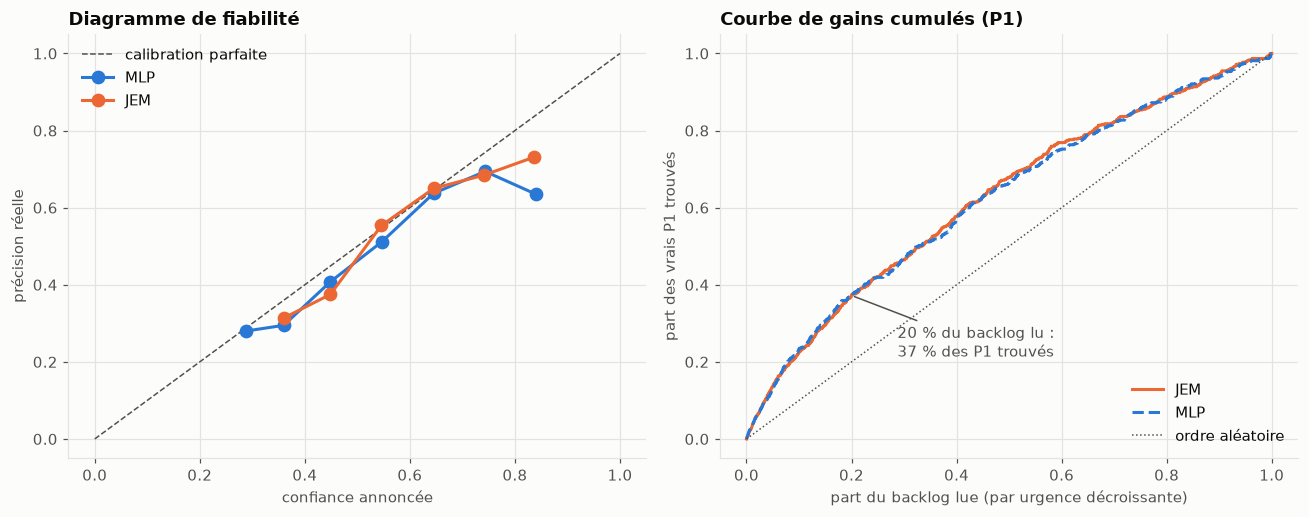

In [5]:
p_mlp, e_mlp = predict(mlp.model, data.x_test)
p_jem, e_jem = predict(jem.model, data.x_test)

def reliability(ax, probs, y, label, color, n_bins=10, **kw):
    conf, correct = probs.max(1), (probs.argmax(1) == y)
    idx = np.clip(np.digitize(conf, np.linspace(0, 1, n_bins + 1)) - 1, 0, n_bins - 1)
    keep = [b for b in range(n_bins) if (idx == b).sum() >= 20]
    ax.plot([conf[idx == b].mean() for b in keep], [correct[idx == b].mean() for b in keep],
            marker="o", label=label, color=color, **kw)

def gains(score, target):
    order = np.argsort(-score)
    return np.r_[0, np.cumsum(target[order]) / target.sum()]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#52514e", linewidth=1, label="calibration parfaite")
reliability(axes[0], p_mlp, y_test, "MLP", MODEL_COLORS["MLP (baseline)"])
reliability(axes[0], p_jem, y_test, "JEM", MODEL_COLORS["JEM"])
axes[0].set_xlabel("confiance annoncée"); axes[0].set_ylabel("précision réelle")
axes[0].set_title("Diagramme de fiabilité"); axes[0].legend()

frac = np.linspace(0, 1, len(y_test) + 1)
g_jem = gains(urgency(p_jem), y_test == 0)
axes[1].plot(frac, g_jem, label="JEM", color=MODEL_COLORS["JEM"])
axes[1].plot(frac, gains(urgency(p_mlp), y_test == 0), label="MLP", color=MODEL_COLORS["MLP (baseline)"], linestyle="--")
axes[1].plot([0, 1], [0, 1], color="#52514e", linestyle=":", linewidth=1, label="ordre aléatoire")
g20 = g_jem[int(0.2 * len(y_test))]
axes[1].annotate(f"20 % du backlog lu :\n{100 * g20:.0f} % des P1 trouvés", (0.2, g20), xytext=(30, -40),
                 textcoords="offset points", color="#52514e", arrowprops={"arrowstyle": "-", "color": "#52514e"})
axes[1].set_xlabel("part du backlog lue (par urgence décroissante)"); axes[1].set_ylabel("part des vrais P1 trouvés")
axes[1].set_title("Courbe de gains cumulés (P1)"); axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

- Les courbes de fiabilité se superposent jusqu'à ~75 % de confiance ; dans la tranche la plus haute, le JEM est moins sur-confiant (~83 % annoncés pour 73 % de réussite, contre 84 % pour 63 %), sur quelques dizaines de bugs.
- En lisant les 20 % de bugs jugés les plus urgents, on trouve **37 % des vrais P1** (20 % au hasard). JEM et MLP sont indiscernables.

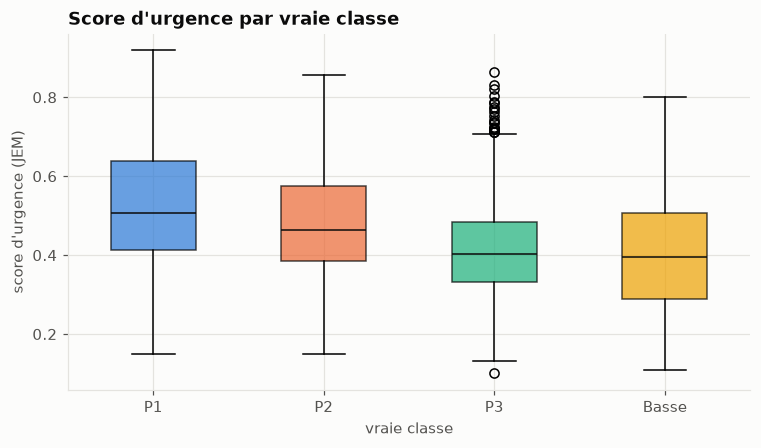

In [6]:
u = urgency(p_jem)
fig, ax = plt.subplots()
bp = ax.boxplot([u[y_test == k] for k in range(len(CLASSES))], tick_labels=CLASSES, patch_artist=True, widths=0.5,
                medianprops={"color": "#0b0b0b"})
for patch, c in zip(bp["boxes"], CLASSES):
    patch.set_facecolor(CLASS_COLORS[c]); patch.set_alpha(0.7)
ax.set_xlabel("vraie classe"); ax.set_ylabel("score d'urgence (JEM)")
ax.set_title("Score d'urgence par vraie classe")
plt.show()

Médianes ordonnées (P1 > P2 > P3 ≈ Basse) mais fort recouvrement : le score sert à **ordonner une file**, pas à trancher un cas isolé.

## 4. Détection des bugs atypiques

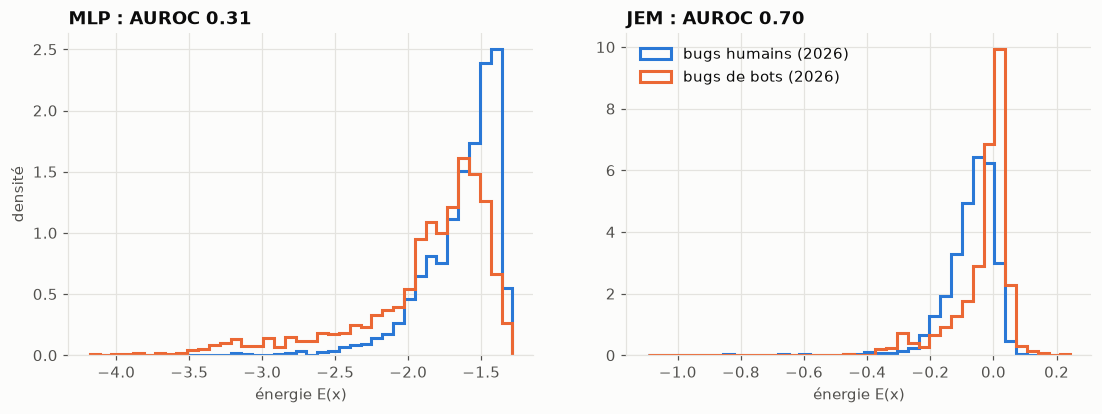

In [7]:
_, eb_mlp = predict(mlp.model, x_bots_test)
_, eb_jem = predict(jem.model, x_bots_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (title, eh, eb) in zip(axes, [("MLP", e_mlp, eb_mlp), ("JEM", e_jem, eb_jem)]):
    bins = np.linspace(min(eh.min(), eb.min()), max(eh.max(), eb.max()), 40)
    ax.hist(eh, bins=bins, density=True, histtype="step", linewidth=2, label="bugs humains (2026)", color=HUMAN_BOT_COLORS["humains"])
    ax.hist(eb, bins=bins, density=True, histtype="step", linewidth=2, label="bugs de bots (2026)", color=HUMAN_BOT_COLORS["bots"])
    ax.set_title(f"{title} : AUROC {ood_auroc(eh, eb):.2f}"); ax.set_xlabel("énergie E(x)")
axes[0].set_ylabel("densité"); axes[1].legend()
plt.show()

In [8]:
bots_2026 = data.bots[data.bots.creation_time >= pd.Timestamp("2026-01-01", tz="UTC")].reset_index(drop=True)
bots_2026["compte"] = bots_2026.creator.str.split("@").str[0]
by_bot = []
for account, grp in bots_2026.groupby("compte"):
    if len(grp) >= 20:
        idx = grp.index.to_numpy()
        by_bot.append({"compte": account, "bugs": len(grp),
                       "AUROC JEM": ood_auroc(e_jem, eb_jem[idx]), "AUROC MLP": ood_auroc(e_mlp, eb_mlp[idx])})
pd.DataFrame(by_bot).sort_values("bugs", ascending=False).round(3)

,compte,bugs,AUROC JEM,AUROC MLP
3,wptsync,722,0.747,0.328
1,intermittent-bug-filer,397,0.691,0.201
0,bugmon,72,0.481,0.621
2,update-bot,20,0.192,0.513


- Bots aux textes stéréotypés bien détectés : `wptsync` (0,75), `intermittent-bug-filer` (0,69).
- `bugmon` (0,48) rejoue des cas de *fuzzing* et dépose de vrais rapports de crash ; `update-bot` (0,19) ouvre des tâches de mise à jour de dépendances au vocabulaire identique à celui des humains.

L'énergie mesure la ressemblance aux bugs humains d'entraînement, pas l'auteur du bug.

In [9]:
threshold = jem.review_threshold
flag = e_jem > threshold
print(f"seuil (95e percentile de l'entraînement) : bugs humains 2026 signalés {flag.mean():.1%}"
      f" | bots 2026 signalés {(eb_jem > threshold).mean():.1%}")
print(f"accuracy sur les bugs humains signalés : {(p_jem.argmax(1)[flag] == y_test[flag]).mean():.3f}"
      f" | sur les autres : {(p_jem.argmax(1)[~flag] == y_test[~flag]).mean():.3f}")
data.test.assign(energie=e_jem).sort_values("energie", ascending=False)[["summary", "component", "label", "energie"]].head(8)

seuil (95e percentile de l'entraînement) : bugs humains 2026 signalés 3.0% | bots 2026 signalés 19.7%
accuracy sur les bugs humains signalés : 0.642 | sur les autres : 0.464


,summary,component,label,energie
349,Incorrect caching of quad gradients in css/css-tables/tentative/paint/background-image...,Graphics: WebRender,P3,0.105529
2198,Consider simplifying Debugger handling of scopes and environments,JavaScript: Debugger API,P2,0.084332
241,View transitions don't deal with reframes of the captured element,CSS Parsing and Computation,P3,0.075543
944,Investigate removing loading add-ons from resource://search-extensions/,Search,P3,0.072631
622,"Rename the functions {Has,Get,CallWIth}IndirectShadowTree",Panning and Zooming,P3,0.067433
769,Telemetry Alert for networking_http_channel_page_open_to_first_sent on 2025-11-15,Networking,Basse,0.066903
795,Telemetry Alert for networking_http_channel_page_open_to_first_sent on 2025-11-15,Networking,Basse,0.066903
364,i2p TLDs are searched for if http:// isn't typed in,Networking,P2,0.065390


Au seuil de l'outil, 3 % des bugs humains et 20 % des bugs de bots de 2026 sont signalés. Les bugs humains signalés sont **mieux** classés que les autres (64 % contre 46 %) : ce sont souvent des rapports semi-automatiques ou très formatés (« Telemetry Alert for … », renommages, tests WPT), inhabituels mais faciles. Le drapeau `needs_review` désigne donc un **bug atypique**, pas une prédiction douteuse.

## Conclusion

| Question | Résultat |
|---|---|
| Classer et ordonner | JEM = MLP ≈ régression logistique (accuracy 0,47, Spearman 0,31, 37 % des P1 dans les 20 % premiers). Plafond lié aux étiquettes et à la dérive 2026. |
| Calibration | Bonne pour les deux réseaux (ECE ≈ 0,05), JEM un peu moins sur-confiant en haut de l'échelle. |
| Bugs atypiques | Gain net : AUROC 0,6-0,7 contre 0,3, sans coût d'inférence supplémentaire. |
| Coût | Entraînement ~13 fois plus long, un hyperparamètre de plus, détection variable d'une époque à l'autre. |

Le JEM ne change pas le plafond de classification ; il ajoute, dans le même réseau, un signal d'atypicité dont le classifieur standard est dépourvu.